# E-to-E backbone method comparison

This notebook treats `mij_EE_matrix.csv` as a directed weighted graph over the excitatory nodes only. The matrix was derived from `mij_matrix.csv` by restricting rows and columns to excitatory senders, then this notebook keeps positive off-diagonal excitatory-to-excitatory transition weights as candidate path edges. That filtering step is intentional: the goal is not to describe every signed connection in the original matrix, but to compare candidate excitatory backbone paths under one shared positive-weight objective.

The notebook compares six backbone-building methods from every excitatory seed:

1. greedy tree/path using the largest outgoing weights to other excitatory neurons  
2. maximum spanning tree-derived path  
3. branch-and-bound search  
4. dynamic programming / beam-limited DP  
5. mixed-integer linear programming with subtour elimination  
6. maximum-weight asymmetric Hamiltonian path  
7. feedback-arc ordering (global vertex ordering, not a path)  

These methods are deliberately different in search style. Greedy construction is a fast local baseline, the maximum spanning tree gives a global non-cycling skeleton, branch-and-bound provides a bounded exhaustive search, dynamic programming gives either an exact subset-state solution or a tractable beam-limited approximation, MILP directly optimizes the unconstrained simple-path objective with linear constraints that prevent subtours, and the Hamiltonian variant asks what happens when every excitatory node must appear exactly once. Keeping all methods in the same notebook makes disagreements easier to inspect, because every result is scored with the same transition matrix, seed definitions, diagonal handling, and output schema.

The seventh method is deliberately not a path method: it maximizes forward-pointing edge weight over a global ordering of all excitatory types, scoring every positive edge rather than only the edges of one selected walk, and it supplies the backbone coordinate the E/I notebook needs.

Reusable implementation lives in `ee_backbone_analysis.py` and `ee_backbone_ordering.py` so this notebook stays focused on configuration, execution, and review. Diagonal entries are ignored here; if a future dataset needs special self-connection handling, handle that as part of dataset preparation before running the analysis.


In [1]:
from pathlib import Path

try:
    import matplotlib.pyplot as plt
except ImportError:
    plt = None

import pandas as pd

from ee_backbone_analysis import (
    EPS,
    beam_dp_path,
    best_mst_path_from_seed,
    branch_bound_path,
    build_disagreement_table,
    build_milp_benchmark_table,
    build_tree_adjacency,
    edges_from_path,
    exact_bitmask_dp_path,
    greedy_path,
    maximum_spanning_tree_edges,
    maximum_weight_asymmetric_hamiltonian_path,
    milp_subtour_elimination_path,
    path_to_records,
    prepare_excitatory_matrix_data,
    write_comparison_outputs,
    write_setup_outputs,
)
from ee_backbone_ordering import (
    dyad_preserving_null_forward_fraction,
    feedback_arc_ordering,
    ordering_edge_table,
    ordering_path_records,
    permutation_null_forward_fraction,
)

INPUT_CSV = Path("matrices/mij_EE_matrix.csv")
OUTDIR = Path("ee_backbone_comparison_outputs")

# Branch-and-bound guardrails. Increase for deeper search.
BB_TIME_LIMIT_PER_SEED = 0.25
BB_NODE_LIMIT_PER_SEED = 50_000

# DP guardrails.
NOTEBOOK_EXACT_DP_MAX_E_NODES = 22
BEAM_WIDTH = 5_000

# MILP guardrails. Increase if any seed returns a non-optimal solver status.
MILP_TIME_LIMIT_PER_SEED = 30
HAMILTONIAN_TIME_LIMIT_PER_SEED = 30

# Feedback-arc ordering guardrails.
ORDERING_RESTARTS = 50
ORDERING_NULL_DRAWS = 2_000
# Exact LOP per surrogate; 100 is the standard used across the corrections pass.
DYAD_NULL_DRAWS = 100


## Prepare data

This section builds the graph that all methods use from `mij_EE_matrix.csv`. Because that file already contains only excitatory rows and columns, the preparation step treats every matrix label as an excitatory node instead of re-inferring excitatory status from the restricted matrix. It then clips the working transition matrix to positive weights and removes the diagonal.

Negative and zero transitions are excluded from the candidate graph because the backbone methods below all optimize a positive path score. The diagonal is set to zero before the methods run, so every selected edge represents a transition between two distinct excitatory nodes. The setup outputs are written before any method-specific search begins; those files make the retained node list and edge set auditable if a later result looks surprising.


In [2]:
data = prepare_excitatory_matrix_data(
    INPUT_CSV,
    eps=EPS,
)
write_setup_outputs(data, OUTDIR)

print(f"E-to-E matrix: {data.full_matrix.shape[0]} x {data.full_matrix.shape[1]}")
print(f"Excitatory nodes retained: {len(data.excitatory_nodes)}")
print(f"Positive E-to-E transitions retained: {(data.transition_weights > EPS).sum()}")
print(f"Positive directed E-to-E transition edges retained: {sum(len(v) for v in data.adjacency.values())}")


E-to-E matrix: 32 x 32
Excitatory nodes retained: 32
Positive E-to-E transitions retained: 355
Positive directed E-to-E transition edges retained: 355


## Method sections

Each method below has its own reasoning note and code cell. The methods are arranged from simpler heuristics to more global searches so the reader can see how much extra complexity changes the selected backbones.

The important comparison point is that all methods receive the same prepared E-to-E graph and report through the same record-building helpers. That keeps the interpretation clean: differences in path length, terminal node, or summed weight should come from the search strategy itself, not from different preprocessing or scoring rules. The separate result tables are combined afterward for output files, disagreement checks, and plots.


## Greedy Tree/Path

The greedy tree/path method starts at each excitatory seed and repeatedly chooses the largest positive outgoing transition to an unvisited excitatory neuron. This is the simplest local rule: at every step it asks, "which reachable excitatory neuron has the strongest direct weight from the current node?" The path stops when there are no positive outgoing transitions to unvisited excitatory nodes. Diagonal/self entries are ignored; scoring is based on transitions between distinct excitatory neurons.

This method is useful because it gives a transparent baseline for the rest of the notebook. If a strong backbone is dominated by a sequence of locally obvious transitions, the greedy path will often recover it quickly and with very little tuning. It also makes failure modes easy to diagnose: when greedy performs poorly, the reason is usually that an early high-weight edge leads into a dead end or prevents access to a better downstream sequence. That makes it a good reference point for judging whether the more expensive searches are adding real value.


In [3]:
greedy_results = []
greedy_edges = []

for seed in range(len(data.excitatory_nodes)):
    path = greedy_path(seed, data)
    method = "greedy_tree_path"
    greedy_results.append(path_to_records(seed, method, path, data))
    greedy_edges.extend(edges_from_path(seed, method, path, data))

greedy_df = pd.DataFrame(greedy_results)
greedy_df.head()


,method,seed,length_edges,n_nodes_visited,transition_weight_sum,summed_weight,terminus,path
0,greedy_tree_path,CA1 Pyramidal,15,16,70463.834562,70463.834562,CA1 Radiatum Giant,CA1 Pyramidal -> MEC LV VI Pyramidal Polymorph...
1,greedy_tree_path,CA1 Radiatum Giant,15,16,70212.697680,70212.697680,CA3 Pyramidal,CA1 Radiatum Giant -> CA1 Pyramidal -> MEC LV ...
2,greedy_tree_path,CA2 Pyramidal,16,17,98803.647145,98803.647145,CA1 Radiatum Giant,CA2 Pyramidal -> CA1 Pyramidal -> MEC LV VI Py...
3,greedy_tree_path,CA3 Granule,15,16,118053.762424,118053.762424,CA1 Radiatum Giant,CA3 Granule -> CA3c Pyramidal -> CA1 Pyramidal...
4,greedy_tree_path,CA3 Pyramidal,15,16,110967.272953,110967.272953,DG Hilar Ectopic Granule,CA3 Pyramidal -> CA2 Pyramidal -> CA1 Pyramida...


## Maximum Spanning Tree

The maximum spanning tree method converts the directed transition matrix into an undirected topology by taking the stronger direction for each pair of excitatory neurons. It then builds the tree that keeps the largest total set of non-cycling connections. For each seed, the reported backbone is the highest-scoring path through that tree. This gives a global skeleton of strong excitatory connectivity, while reported path scores use the original directed transition weights between distinct nodes.

This works as a backbone heuristic because a spanning tree removes cycles and redundant alternatives while preserving a connected set of high-weight relationships. It is not trying to solve the same directed simple-path problem exactly; instead, it asks which strong pairwise links survive when the graph is forced into a sparse, interpretable skeleton. The seed-specific path is then chosen inside that skeleton, which can reveal broad corridors of connectivity even when the full directed graph has many competing edges. The tradeoff is that directionality influences scoring but not tree construction, so the method is best read as a structural comparison rather than a directed optimum.


In [4]:
mst_edges = maximum_spanning_tree_edges(data.transition_weights)
tree_adj = build_tree_adjacency(len(data.excitatory_nodes), mst_edges)

mst_results = []
mst_path_edges = []
for seed in range(len(data.excitatory_nodes)):
    path = best_mst_path_from_seed(seed, tree_adj, data)
    method = "maximum_spanning_tree"
    mst_results.append(path_to_records(seed, method, path, data))
    mst_path_edges.extend(edges_from_path(seed, method, path, data))

mst_df = pd.DataFrame(mst_results)
mst_df.head()


,method,seed,length_edges,n_nodes_visited,transition_weight_sum,summed_weight,terminus,path
0,maximum_spanning_tree,CA1 Pyramidal,6,7,58407.132798,58407.132798,CA3 Granule,CA1 Pyramidal -> CA3c Pyramidal -> DG Granule ...
1,maximum_spanning_tree,CA1 Radiatum Giant,3,4,99174.254566,99174.254566,MEC LV VI Pyramidal Polymorphic,CA1 Radiatum Giant -> CA3c Pyramidal -> CA1 Py...
2,maximum_spanning_tree,CA2 Pyramidal,3,4,101386.520981,101386.520981,MEC LV VI Pyramidal Polymorphic,CA2 Pyramidal -> CA3c Pyramidal -> CA1 Pyramid...
3,maximum_spanning_tree,CA3 Granule,7,8,111573.689757,111573.689757,MEC LV VI Pyramidal Polymorphic,CA3 Granule -> MEC LII Stellate -> EC LI II Mu...
4,maximum_spanning_tree,CA3 Pyramidal,4,5,113853.823042,113853.823042,MEC LV VI Pyramidal Polymorphic,CA3 Pyramidal -> CA2 Pyramidal -> CA3c Pyramid...


## Branch-and-Bound

Branch-and-bound searches the space of simple directed paths from each seed while keeping the best path found so far. At each partial path, it estimates an optimistic upper bound on how much more score could still be gained; if that bound cannot beat the current best path, the branch is pruned. This gives a more exhaustive search than greedy methods, with time and node-count guardrails to keep the run practical.

The key idea is that many partial paths can be ruled out without explicitly completing them. If even the best possible extension of a partial path cannot exceed the incumbent score, every longer path under that branch is irrelevant for the current objective. That pruning makes an otherwise explosive simple-path search more manageable while preserving exactness when the search finishes completely. The notebook records both the number of states visited and the stop status, because a result stopped by `time_limit` or `node_limit` should be read as the best path found under the guardrails rather than a proven optimum.

The optimistic bound must be admissible for the pruning to be safe. A continuation from the current node through `k` unvisited nodes uses the edge leaving the current node and the edges leaving the first `k-1` of those nodes, so the bound charges `max_extension` for the current node *and* for every unvisited node. An earlier version of `branch_bound_path` summed only over unvisited nodes; that omitted the edge actually leaving the current node and could prune the optimum even on a three-node graph. With the corrected bound, branch-and-bound agrees exactly with the bitmask dynamic program on every completed run over several hundred random test graphs.


In [5]:
bb_results = []
bb_edges = []

for seed in range(len(data.excitatory_nodes)):
    path, score, states, status = branch_bound_path(
        seed,
        data,
        time_limit=BB_TIME_LIMIT_PER_SEED,
        node_limit=BB_NODE_LIMIT_PER_SEED,
    )
    method = "branch_and_bound"
    bb_results.append(
        path_to_records(
            seed,
            method,
            path,
            data,
            {
                "bb_states_seen": states,
                "bb_status": status,
                "bb_score": score,
            },
        )
    )
    bb_edges.extend(edges_from_path(seed, method, path, data))

bb_df = pd.DataFrame(bb_results)
bb_df.head()


,method,seed,length_edges,n_nodes_visited,transition_weight_sum,summed_weight,terminus,path,bb_states_seen,bb_status,bb_score
0,branch_and_bound,CA1 Pyramidal,28,29,141382.369477,141382.369477,CA3 Granule,CA1 Pyramidal -> MEC LV VI Pyramidal Polymorph...,50000,node_limit,141382.369477
1,branch_and_bound,CA1 Radiatum Giant,29,30,141434.895546,141434.895546,CA3 Granule,CA1 Radiatum Giant -> CA1 Pyramidal -> MEC LV ...,50000,node_limit,141434.895546
2,branch_and_bound,CA2 Pyramidal,28,29,125961.920981,125961.920981,CA1 Radiatum Giant,CA2 Pyramidal -> CA1 Pyramidal -> MEC LV VI Py...,50000,node_limit,125961.920981
3,branch_and_bound,CA3 Granule,30,31,217874.044016,217874.044016,CA1 Radiatum Giant,CA3 Granule -> CA3c Pyramidal -> CA1 Pyramidal...,50000,node_limit,217874.044016
4,branch_and_bound,CA3 Pyramidal,27,28,134924.381927,134924.381927,DG Mossy,CA3 Pyramidal -> CA2 Pyramidal -> CA1 Pyramida...,50000,node_limit,134924.381927


## Dynamic Programming

Dynamic programming tracks the best score for path states defined by visited-node sets and the current terminal node. When the excitatory set is small enough, this gives an exact bitmask dynamic program over simple directed paths: each state says which nodes have already been used and where the path currently ends, and the recurrence extends that state by one valid unvisited outgoing neighbor. Because the best score for a state summarizes all earlier ways of reaching the same visited set and terminal node, dominated histories do not need to be kept.

For larger excitatory sets, the number of possible visited sets grows exponentially, so the notebook switches to a beam-limited dynamic program that keeps only the strongest states at each expansion depth. The beam version preserves the same state logic but intentionally trades exactness for tractability. That means it can return lower path weights than other methods when the beam prunes states that look weaker early but would have led to stronger later continuations. In this notebook, the DP result should therefore be read as exact only when `dp_mode == "exact"`; when `dp_mode == "beam"`, it is a heuristic comparison point rather than the final maximizing benchmark.

A closely related computation appears in Held and Karp's dynamic programming approach to sequencing problems, which also indexes subproblem values by a subset of visited items and a terminal item. The objective here is adapted to a best positive directed path rather than a tour, but the state representation is the same core idea.


In [6]:
dp_results = []
dp_edges = []

for seed in range(len(data.excitatory_nodes)):
    if len(data.excitatory_nodes) <= NOTEBOOK_EXACT_DP_MAX_E_NODES:
        path, score, mode = exact_bitmask_dp_path(seed, data)
    else:
        path, score, mode = beam_dp_path(seed, data, beam_width=BEAM_WIDTH)
    method = "dynamic_programming"
    dp_results.append(
        path_to_records(
            seed,
            method,
            path,
            data,
            {
                "dp_mode": mode,
                "dp_score": score,
            },
        )
    )
    dp_edges.extend(edges_from_path(seed, method, path, data))

dp_df = pd.DataFrame(dp_results)
dp_df.head()


,method,seed,length_edges,n_nodes_visited,transition_weight_sum,summed_weight,terminus,path,dp_mode,dp_score
0,dynamic_programming,CA1 Pyramidal,4,5,61577.719577,61577.719577,DG Mossy,CA1 Pyramidal -> EC LV Deep Pyramidal -> MEC L...,beam_width_5000,61577.719577
1,dynamic_programming,CA1 Radiatum Giant,5,6,61630.245646,61630.245646,DG Mossy,CA1 Radiatum Giant -> CA1 Pyramidal -> EC LV D...,beam_width_5000,61630.245646
2,dynamic_programming,CA2 Pyramidal,5,6,145723.683747,145723.683747,DG Mossy,CA2 Pyramidal -> CA3c Pyramidal -> CA1 Pyramid...,beam_width_5000,145723.683747
3,dynamic_programming,CA3 Granule,6,7,150286.637990,150286.637990,DG Mossy,CA3 Granule -> CA3 Pyramidal -> CA3c Pyramidal...,beam_width_5000,150286.637990
4,dynamic_programming,CA3 Pyramidal,5,6,150285.695971,150285.695971,DG Mossy,CA3 Pyramidal -> CA3c Pyramidal -> CA1 Pyramid...,beam_width_5000,150285.695971


## MILP with Subtour Elimination

The mixed-integer linear program directly models the maximum-weight simple directed path from each seed. It uses a binary variable for each allowed directed edge, a binary variable for each included node, and an order variable for each node. The objective maximizes the sum of selected positive transition weights.

The degree constraints force the selected edges to form one path that starts at the seed: the seed has no incoming edge, every other selected node has exactly one incoming edge, and every selected node has at most one outgoing edge. The MTZ-style order constraints provide subtour elimination. If edge `i -> j` is selected, then `j` must appear later than `i` in the path order; a directed cycle would require the order numbers to increase all the way around the cycle and return to the starting node, which is impossible.

This is the most direct optimizer in the notebook, but its status field needs care. `pulp.LpStatus[problem.status]` reports `Optimal` both when CBC proves optimality **and** when CBC stops on the time limit holding a feasible incumbent, so it is not a certificate. The helper module now reads `problem.sol_status` instead, which distinguishes `Optimal Solution Found` from `Solution Found`, and records the result in the boolean `milp_proven_optimal`.

Only rows with `milp_proven_optimal == True` are exact maximum-weight simple paths. For any seed where it is `False`, raise `MILP_TIME_LIMIT_PER_SEED` and rerun before using that seed as a benchmark; until then its `weight_gap_to_milp_incumbent` is a gap to an incumbent and may be negative.


In [7]:
milp_results = []
milp_edges = []

for seed in range(len(data.excitatory_nodes)):
    path, score, status, objective, proven_optimal = milp_subtour_elimination_path(
        seed,
        data,
        time_limit=MILP_TIME_LIMIT_PER_SEED,
    )
    method = "milp_subtour_elimination"
    milp_results.append(
        path_to_records(
            seed,
            method,
            path,
            data,
            {
                "milp_status": status,
                "milp_score": score,
                "milp_objective": objective,
                "milp_time_limit_seconds": MILP_TIME_LIMIT_PER_SEED,
                "milp_proven_optimal": proven_optimal,
            },
        )
    )
    milp_edges.extend(edges_from_path(seed, method, path, data))

milp_df = pd.DataFrame(milp_results)
n_proven = int(milp_df['milp_proven_optimal'].sum())
print(f"MILP: {n_proven} of {len(milp_df)} seeds PROVEN optimal "
      f"({len(milp_df) - n_proven} stopped on the time limit with an incumbent).")
milp_df.head()


MILP: 30 of 32 seeds PROVEN optimal (2 stopped on the time limit with an incumbent).


,method,seed,length_edges,n_nodes_visited,transition_weight_sum,summed_weight,terminus,path,milp_status,milp_score,milp_objective,milp_time_limit_seconds,milp_proven_optimal
0,milp_subtour_elimination,CA1 Pyramidal,29,30,155964.945692,155964.945692,CA3 Granule,CA1 Pyramidal -> MEC LV VI Pyramidal Polymorph...,Optimal Solution Found,155964.945692,155964.945692,30,True
1,milp_subtour_elimination,CA1 Radiatum Giant,28,29,148527.967630,148527.967630,CA3 Granule,CA1 Radiatum Giant -> CA1 Pyramidal -> MEC LV ...,Solution Found,148527.967630,148527.967630,30,False
2,milp_subtour_elimination,CA2 Pyramidal,28,29,217745.478572,217745.478572,DG Hilar Ectopic Granule,CA2 Pyramidal -> CA3 Pyramidal -> CA3c Pyramid...,Optimal Solution Found,217745.478572,217745.478572,30,True
3,milp_subtour_elimination,CA3 Granule,29,30,224463.251854,224463.251854,DG Hilar Ectopic Granule,CA3 Granule -> CA3 Pyramidal -> CA2 Pyramidal ...,Optimal Solution Found,224463.251854,224463.251854,30,True
4,milp_subtour_elimination,CA3 Pyramidal,28,29,224462.309835,224462.309835,DG Hilar Ectopic Granule,CA3 Pyramidal -> CA2 Pyramidal -> CA3c Pyramid...,Optimal Solution Found,224462.309835,224462.309835,30,True


## Maximum-Weight Asymmetric Hamiltonian Path

The maximum-weight asymmetric Hamiltonian path method is another MILP, but it adds a stricter requirement than the unconstrained simple-path MILP above: every excitatory node must be visited exactly once. The graph remains asymmetric because the selected edge `i -> j` and the reverse edge `j -> i` can have different weights, and the solver is free to choose whichever directed ordering maximizes total transition weight from the fixed seed.

The formulation uses one binary variable per allowed directed edge and one order variable per node. Each non-seed node must have exactly one incoming edge, the seed has no incoming edge, every node has at most one outgoing edge, and the total number of selected edges is `n - 1`. MTZ-style order constraints eliminate subtours by forcing each selected edge to move forward in the path order.

This method answers a different question from the previous MILP. The unconstrained MILP can stop before visiting all nodes if adding another node would require a weak continuation, while the Hamiltonian path is forced to include all 32 excitatory nodes. Because of that forced coverage, it can be biologically useful as a complete ordering, but it should not be expected to dominate the unconstrained MILP on summed path weight.


In [8]:
hamiltonian_results = []
hamiltonian_edges = []

for seed in range(len(data.excitatory_nodes)):
    (
        path,
        score,
        status,
        objective,
        proven_optimal,
    ) = maximum_weight_asymmetric_hamiltonian_path(
        seed,
        data,
        time_limit=HAMILTONIAN_TIME_LIMIT_PER_SEED,
    )
    method = "maximum_weight_asymmetric_hamiltonian_path"
    hamiltonian_results.append(
        path_to_records(
            seed,
            method,
            path,
            data,
            {
                "hamiltonian_status": status,
                "hamiltonian_score": score,
                "hamiltonian_objective": objective,
                "hamiltonian_time_limit_seconds": HAMILTONIAN_TIME_LIMIT_PER_SEED,
                "hamiltonian_proven_optimal": proven_optimal,
            },
        )
    )
    hamiltonian_edges.extend(edges_from_path(seed, method, path, data))

hamiltonian_df = pd.DataFrame(hamiltonian_results)
n_proven = int(hamiltonian_df['hamiltonian_proven_optimal'].sum())
print(f"Hamiltonian: {n_proven} of {len(hamiltonian_df)} seeds PROVEN optimal.")
hamiltonian_df.head()


Hamiltonian: 31 of 32 seeds PROVEN optimal.


,method,seed,length_edges,n_nodes_visited,transition_weight_sum,summed_weight,terminus,path,hamiltonian_status,hamiltonian_score,hamiltonian_objective,hamiltonian_time_limit_seconds,hamiltonian_proven_optimal
0,maximum_weight_asymmetric_hamiltonian_path,CA1 Pyramidal,31,32,138363.442055,138363.442055,CA1 Radiatum Giant,CA1 Pyramidal -> MEC LV VI Pyramidal Polymorph...,Optimal Solution Found,138363.442055,138363.442055,30,True
1,maximum_weight_asymmetric_hamiltonian_path,CA1 Radiatum Giant,31,32,138407.680397,138407.680397,SUB CA1 Projecting Pyramidal,CA1 Radiatum Giant -> CA1 Pyramidal -> MEC LV ...,Optimal Solution Found,138407.680397,138407.680397,30,True
2,maximum_weight_asymmetric_hamiltonian_path,CA2 Pyramidal,31,32,184864.168859,184864.168859,CA1 Radiatum Giant,CA2 Pyramidal -> DG Mossy -> DG Semilunar Gran...,Optimal Solution Found,184864.168859,184864.168859,30,True
3,maximum_weight_asymmetric_hamiltonian_path,CA3 Granule,31,32,194266.470579,194266.470579,CA1 Radiatum Giant,CA3 Granule -> CA3 Pyramidal -> CA2 Pyramidal ...,Optimal Solution Found,194266.470579,194266.470579,30,True
4,maximum_weight_asymmetric_hamiltonian_path,CA3 Pyramidal,31,32,138415.954819,138415.954819,DG Hilar Ectopic Granule,CA3 Pyramidal -> CA2 Pyramidal -> CA3 Granule ...,Optimal Solution Found,138415.954819,138415.954819,30,True


## Feedback-Arc Ordering (Vahidi 2025)

The six methods above all answer the same question: which single walk through the graph carries the most weight? This section asks a different one. Instead of selecting a path, it searches for an **ordering of all 32 excitatory types** that maximizes the total weight of forward-pointing edges, equivalently minimizing the weight of the feedback arc set.

The distinction matters for how much of the data each objective uses. A maximum-weight Hamiltonian path scores the 31 edges it selects and ignores the other 324 positive transitions. A feedback-arc ordering scores *every* positive edge against the ordering, so it answers "what is the dominant direction of excitatory flow through these neuron types" rather than "what is the single heaviest route through them". That is closer to the backbone question this project is actually asking, and it produces a coordinate that the E/I notebook needs as `BACKBONE_LABELS`.

Two structural facts do most of the work.

First, the problem **decomposes exactly over strongly connected components**. All edges between distinct SCCs can be made forward simultaneously by ordering the SCCs topologically in the condensation, so no optimal ordering ever pays for them; feedback weight is incurred only within SCCs. This is exact rather than heuristic, and the SCC structure is itself a result worth reporting.

Second, once an ordering is fixed, the forward-edge subgraph is **acyclic**, so the maximum-weight simple path from any seed within it is solvable exactly in `O(V + E)` by one sweep along the ordering. A forward walk can never revisit a node, so the NP-hardness of the unrestricted simple-path problem turns out to be an artifact of allowing backward steps. These per-seed paths carry a genuine optimality guarantee conditional on the ordering, which none of the heuristic methods above can claim.

The search follows the three ingredients Vahidi combines: a greedy construction (a weighted variant of the Eades-Lin-Smyth heuristic), gain-aware local refinement by best-position reinsertion, and SCC-based decomposition. Because refinement converges to a local optimum of the reinsertion neighbourhood, the greedy start is supplemented with randomized restarts.

Reference: Vahidi, S. (2025). *Feedforward Ordering in Neural Connectomes via Feedback Arc Minimization.* arXiv:2506.13799 — developed and evaluated on the FlyWire connectome.


In [9]:
ordering = feedback_arc_ordering(
    data,
    n_restarts=ORDERING_RESTARTS,
    random_seed=2026,
)

print(f"Strongly connected components: {len(ordering.scc_sizes)}")
print(f"Component sizes: {ordering.scc_sizes}")
print(f"Refinement passes to convergence: {ordering.refinement_passes}")
print()
for key, value in ordering.metrics.items():
    if isinstance(value, float):
        print(f"  {key:26s} {value:,.4f}")
    else:
        print(f"  {key:26s} {value:,}")

ordering_positions = ordering.position_table()
ordering_positions.head(10)


Strongly connected components: 1
Component sizes: [32]
Refinement passes to convergence: 0

  n_edges                    355
  n_forward_edges            208
  n_feedback_edges           147
  forward_weight             748,421.4165
  feedback_weight            39,719.2234
  total_weight               788,140.6399
  forward_weight_fraction    0.9496
  feedback_weight_fraction   0.0504
  lop_forward_fraction       0.9496
  lop_upper_bound            0.9496
  lop_gap                    0.0000
  lop_certified              1


,position,node,node_index
0,0,EC LI II Pyramidal Fan,11
1,1,EC LI II Multipolar Pyramidal,10
2,2,EC LII III Pyramidal Tripolar,12
3,3,MEC LII Stellate,24
4,4,EC LIII Pyramidal Stellate,14
5,5,CA3 Pyramidal,4
6,6,CA3c Pyramidal,5
7,7,CA2 Pyramidal,2
8,8,CA1 Radiatum Giant,1
9,9,CA1 Pyramidal,0


### Is the ordering better than chance?

A forward-weight fraction only means something relative to what an arbitrary ordering achieves. The comparison below permutes the node labels and recomputes the fraction, using the empirical p-value `(1 + #{null >= observed}) / (1 + n_null)` prescribed in the null-model section of the deterministic/stochastic branch notebook, so the p-value is never exactly zero.


In [10]:
ordering_null = permutation_null_forward_fraction(
    data.transition_weights,
    ordering.metrics["forward_weight_fraction"],
    n_null=ORDERING_NULL_DRAWS,
    random_seed=2026,
)

print(f"observed forward-weight fraction: {ordering.metrics['forward_weight_fraction']:.4f}")
for key, value in ordering_null.items():
    print(f"  {key:34s} {value:.6g}")


# --- Corrections pass 2026-09-17 -------------------------------------------
# The permutation null above asks only "is this ordering better than a random
# ordering". The answer is yes for any graph with any feedforward structure at
# all, so it tests nothing about this connectome. The null below preserves every
# node's in-degree and out-degree AND the mutual/asymmetric dyad census, and
# orders each surrogate with the same exact LOP solver used on the observed
# graph. Report this one.
#
# Two failure modes it fixes. A plain directed edge swap destroys roughly 60% of
# the mutual dyads, and a mutual dyad contributes one backward edge under ANY
# ordering, so the old surrogate was artificially easy to make feedforward. And
# a heuristic on the observed side with a heuristic on the null side does not
# cancel -- the gap to the optimum differs between the two ensembles.
#
# `z_vs_null_upper_bound` is the conservative figure: the certified observed
# optimum against each surrogate's MILP dual bound rather than its incumbent.
ordering_dyad_null = dyad_preserving_null_forward_fraction(
    data.transition_weights,
    ordering.metrics["forward_weight_fraction"],
    n_null=DYAD_NULL_DRAWS,
    random_seed=2026,
)

print()
print("degree- and dyad-preserving null (exact LOP on both sides)")
print(f"observed forward-weight fraction: "
      f"{ordering.metrics['forward_weight_fraction']:.6f}")
for key, value in ordering_dyad_null.items():
    print(f"  {key:36s} {value}")


observed forward-weight fraction: 0.9496
  null_n                             2000
  null_mean_forward_fraction         0.498314
  null_sd_forward_fraction           0.121932
  null_max_forward_fraction          0.814808
  observed_percentile_in_null        100
  empirical_p_forward_fraction       0.00049975



degree- and dyad-preserving null (exact LOP on both sides)
observed forward-weight fraction: 0.949604
  null_n                               100
  null_model                           in/out-degree and dyad-census preserving rewire, exact LOP ordering
  null_dyad_census_preserved           True
  null_mean_forward_fraction           0.9441243021655691
  null_sd_forward_fraction             0.005649301667023637
  null_max_forward_fraction            0.9552937093103624
  z_forward_fraction                   0.9699582113579106
  empirical_p_forward_fraction         0.16831683168316833
  null_mean_upper_bound                0.9441243021655691
  null_sd_upper_bound                  0.005649301667023637
  z_vs_null_upper_bound                0.9699582113579106
  empirical_p_vs_null_upper_bound      0.16831683168316833


### Per-seed paths under the ordering

For comparability with the other methods, each seed also gets the exact maximum-weight *forward* path under the ordering. Read these as "the heaviest strictly-feedforward route from this seed", not as a competitor on `summed_weight`. They are systematically shorter and lighter than the free-path methods by construction: a seed placed late in the ordering has few forward options left, whereas the MILP may travel backward through the ordering as often as it likes. The value of this method is the ordering and its feedback-weight fraction, not its position in the path-weight ranking.


In [11]:
ordering_results, ordering_edges = ordering_path_records(ordering, data)
ordering_df = pd.DataFrame(ordering_results)

ordering_all_edges = ordering_edge_table(ordering, data)
print("Heaviest feedback (backward) transitions under the ordering:")
print(
    ordering_all_edges[ordering_all_edges["direction"] == "feedback"]
    .head(10)[["sender", "receiver", "displacement", "weight"]]
    .to_string(index=False)
)

ordering_df.head()


Heaviest feedback (backward) transitions under the ordering:
                             sender                      receiver  displacement      weight
      EC LII III Pyramidal Tripolar EC LI II Multipolar Pyramidal            -1 4216.395704
                         DG Granule                 CA2 Pyramidal           -21 3360.733225
      EC LI II Multipolar Pyramidal        EC LI II Pyramidal Fan            -1 2685.199893
                      CA2 Pyramidal                CA3c Pyramidal            -1 2212.266415
                         DG Granule                CA3c Pyramidal           -22 1802.511478
         MEC LIII Complex Pyramidal              MEC LII Stellate           -16 1193.084720
                      CA2 Pyramidal                 CA3 Pyramidal            -2 1188.458574
                   MEC LII Stellate EC LI II Multipolar Pyramidal            -2 1179.869599
EC LIV VI Deep Multipolar Principal    EC LIII Pyramidal Stellate            -6 1011.545714
                   

,method,seed,length_edges,n_nodes_visited,transition_weight_sum,summed_weight,terminus,path,ordering_dag_score,ordering_exact_within_ordering,ordering_forward_weight_fraction,seed_position
0,feedback_arc_ordering,CA1 Pyramidal,8,9,63957.554943,63957.554943,DG Hilar Ectopic Granule,CA1 Pyramidal -> EC LIV VI Deep Multipolar Pri...,63957.554943,True,0.949604,9
1,feedback_arc_ordering,CA1 Radiatum Giant,9,10,64010.081011,64010.081011,DG Hilar Ectopic Granule,CA1 Radiatum Giant -> CA1 Pyramidal -> EC LIV ...,64010.081011,True,0.949604,8
2,feedback_arc_ordering,CA2 Pyramidal,9,10,69490.118132,69490.118132,DG Hilar Ectopic Granule,CA2 Pyramidal -> CA1 Pyramidal -> EC LIV VI De...,69490.118132,True,0.949604,7
3,feedback_arc_ordering,CA3 Granule,0,1,0.000000,0.000000,CA3 Granule,CA3 Granule,0.000000,True,0.949604,31
4,feedback_arc_ordering,CA3 Pyramidal,10,11,156341.443346,156341.443346,DG Hilar Ectopic Granule,CA3 Pyramidal -> CA3c Pyramidal -> CA1 Pyramid...,156341.443346,True,0.949604,5


## Combine method results

This section stacks the per-method result tables into one long comparison table and combines all selected edges into a single edge table. The long table is the most convenient shape for filtering by seed or method, while the edge table preserves the actual step-by-step transitions selected by each search.

Combining results only after every method has run avoids accidental cross-method dependencies. It also lets downstream outputs use one shared schema for path length, node count, terminal node, summed weight, and method-specific metadata such as branch-and-bound stop status, DP mode, MILP solver status, or Hamiltonian solver status.


In [12]:
comparison = pd.concat(
    [greedy_df, mst_df, bb_df, dp_df, milp_df, hamiltonian_df, ordering_df],
    ignore_index=True,
)
edge_table = pd.DataFrame(
    greedy_edges
    + mst_path_edges
    + bb_edges
    + dp_edges
    + milp_edges
    + hamiltonian_edges
    + ordering_edges
)

comparison.sort_values(["seed", "method"]).reset_index(drop=True).head(20)


,method,seed,length_edges,n_nodes_visited,transition_weight_sum,summed_weight,terminus,path,bb_states_seen,bb_status,...,milp_proven_optimal,hamiltonian_status,hamiltonian_score,hamiltonian_objective,hamiltonian_time_limit_seconds,hamiltonian_proven_optimal,ordering_dag_score,ordering_exact_within_ordering,ordering_forward_weight_fraction,seed_position
0,branch_and_bound,CA1 Pyramidal,28,29,141382.369477,141382.369477,CA3 Granule,CA1 Pyramidal -> MEC LV VI Pyramidal Polymorph...,50000.0,node_limit,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,dynamic_programming,CA1 Pyramidal,4,5,61577.719577,61577.719577,DG Mossy,CA1 Pyramidal -> EC LV Deep Pyramidal -> MEC L...,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,feedback_arc_ordering,CA1 Pyramidal,8,9,63957.554943,63957.554943,DG Hilar Ectopic Granule,CA1 Pyramidal -> EC LIV VI Deep Multipolar Pri...,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,63957.554943,True,0.949604,9.0
3,greedy_tree_path,CA1 Pyramidal,15,16,70463.834562,70463.834562,CA1 Radiatum Giant,CA1 Pyramidal -> MEC LV VI Pyramidal Polymorph...,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,maximum_spanning_tree,CA1 Pyramidal,6,7,58407.132798,58407.132798,CA3 Granule,CA1 Pyramidal -> CA3c Pyramidal -> DG Granule ...,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,maximum_weight_asymmetric_hamiltonian_path,CA1 Pyramidal,31,32,138363.442055,138363.442055,CA1 Radiatum Giant,CA1 Pyramidal -> MEC LV VI Pyramidal Polymorph...,NaN,NaN,...,NaN,Optimal Solution Found,138363.442055,138363.442055,30.0,True,NaN,NaN,NaN,NaN
6,milp_subtour_elimination,CA1 Pyramidal,29,30,155964.945692,155964.945692,CA3 Granule,CA1 Pyramidal -> MEC LV VI Pyramidal Polymorph...,NaN,NaN,...,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,branch_and_bound,CA1 Radiatum Giant,29,30,141434.895546,141434.895546,CA3 Granule,CA1 Radiatum Giant -> CA1 Pyramidal -> MEC LV ...,50000.0,node_limit,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,dynamic_programming,CA1 Radiatum Giant,5,6,61630.245646,61630.245646,DG Mossy,CA1 Radiatum Giant -> CA1 Pyramidal -> EC LV D...,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,feedback_arc_ordering,CA1 Radiatum Giant,9,10,64010.081011,64010.081011,DG Hilar Ectopic Granule,CA1 Radiatum Giant -> CA1 Pyramidal -> EC LIV ...,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,64010.081011,True,0.949604,8.0


## Write outputs

This section writes the comparison artifacts to `ee_backbone_comparison_outputs`. The long file keeps one row per seed-method result, the wide file places methods side by side for each seed, the edge file records selected transitions, the method summary aggregates performance across seeds, the branch-and-bound/DP disagreement file preserves the earlier diagnostic comparison, and the MILP benchmark file measures each non-benchmark method's gap to the unconstrained MILP solution.

Writing these files makes the notebook useful as both an interactive analysis and a reproducible handoff artifact. A reader can inspect the notebook narrative, rerun the computations, or load the CSV outputs directly into another plotting or review workflow without reimplementing the method comparison.


In [13]:
wide, method_summary = write_comparison_outputs(comparison, edge_table, OUTDIR)

# Feedback-arc ordering artifacts. backbone_ordering.csv is the ordering the E/I
# notebook should load into BACKBONE_LABELS.
ordering_positions.to_csv(OUTDIR / "backbone_ordering.csv", index=False)
ordering_all_edges.to_csv(OUTDIR / "ordering_edge_directions.csv", index=False)
pd.Series(ordering.metrics).to_csv(OUTDIR / "ordering_metrics.csv")
pd.Series(ordering_null).to_csv(OUTDIR / "ordering_permutation_null.csv")

print("Wrote:")
for name in [
    "method_comparison_long.csv",
    "method_comparison_wide.csv",
    "all_methods_edges.csv",
    "method_summary.csv",
    "bb_dp_disagreements.csv",
    "milp_benchmark_gaps.csv",
    "backbone_ordering.csv",
    "ordering_edge_directions.csv",
    "ordering_metrics.csv",
    "ordering_permutation_null.csv",
]:
    print(f"  {OUTDIR / name}")

method_summary


Wrote:
  ee_backbone_comparison_outputs/method_comparison_long.csv
  ee_backbone_comparison_outputs/method_comparison_wide.csv
  ee_backbone_comparison_outputs/all_methods_edges.csv
  ee_backbone_comparison_outputs/method_summary.csv
  ee_backbone_comparison_outputs/bb_dp_disagreements.csv
  ee_backbone_comparison_outputs/milp_benchmark_gaps.csv
  ee_backbone_comparison_outputs/backbone_ordering.csv
  ee_backbone_comparison_outputs/ordering_edge_directions.csv
  ee_backbone_comparison_outputs/ordering_metrics.csv
  ee_backbone_comparison_outputs/ordering_permutation_null.csv


,method,objective,comparable_on_summed_weight,n_seeds,mean_length,median_length,mean_transition_weight,mean_summed_weight,median_summed_weight,max_summed_weight,n_unique_termini
0,branch_and_bound,max-weight simple path (exact if bb_status == ...,True,32,28.68750,29.0,182881.222583,182881.222583,173585.697193,239308.674189,3
1,dynamic_programming,max-weight simple path (exact only if dp_mode ...,True,32,4.46875,4.0,109772.178845,109772.178845,105454.361880,150349.914750,3
2,feedback_arc_ordering,max forward-edge weight over a GLOBAL ORDERING...,False,32,5.43750,4.5,54257.146287,54257.146287,52056.947166,199781.077902,4
3,greedy_tree_path,max-weight simple path (local heuristic),True,32,16.68750,16.0,125314.241109,125314.241109,121527.333900,195127.342493,4
4,maximum_spanning_tree,"undirected high-weight skeleton, then best pat...",True,32,5.46875,6.0,95745.166277,95745.166277,109051.220211,114610.215861,2
5,maximum_weight_asymmetric_hamiltonian_path,max-weight path visiting every node once,True,32,31.00000,31.0,203895.571912,203895.571912,222249.220812,223058.618453,4
6,milp_subtour_elimination,max-weight simple path (exact if milp_proven_o...,True,32,28.43750,28.0,228294.300955,228294.300955,241065.042047,241901.420168,4


## MILP benchmark gaps

This section compares every non-benchmark method against the unconstrained MILP result for the same seed. When `milp_proven_optimal` is True, `weight_gap_to_milp_incumbent` is the amount of path weight left on the table under the same positive E-to-E graph. When it is False the MILP value is only an incumbent, the "gap" is measured against that incumbent, and it can be negative because another method may have found a better feasible path than the one CBC happened to hold when its clock ran out. `build_milp_benchmark_table` prints a note listing any such seeds, and raises if a method ever beats a *proven* optimum, which would indicate a formulation or scoring bug rather than a solver limit.

This view is more useful than treating the dynamic-programming output as the benchmark when the notebook is in beam mode. Beam DP is a heuristic at this graph size, while the unconstrained MILP provides an exact reference whenever the solver proves optimality. The Hamiltonian method is included in the gap table too, but its gap should be interpreted as the cost of forcing complete node coverage rather than as a failure to solve the same unconstrained problem.


In [14]:
milp_benchmark = build_milp_benchmark_table(comparison)
milp_benchmark.sort_values("weight_gap_to_milp_incumbent", ascending=False).head(20)


,seed,method,method_summed_weight,milp_summed_weight,weight_gap_to_milp_incumbent,milp_proven_optimal,gap_is_certified,method_length_edges,milp_length_edges,method_terminus,milp_terminus,milp_status
80,EC LIII Pyramidal,feedback_arc_ordering,47.900876,241759.069451,241711.168574,True,True,1,28,MEC LV VI Pyramidal Polymorphic,CA3 Granule,Optimal Solution Found
140,MEC LII Oblique Pyramidal,feedback_arc_ordering,123.646502,241816.876248,241693.229746,True,True,3,29,MEC LV VI Pyramidal Polymorphic,DG Hilar Ectopic Granule,Optimal Solution Found
92,EC LIII Stellate,feedback_arc_ordering,113.320885,241581.790711,241468.469825,True,True,2,29,MEC LV VI Pyramidal Polymorphic,CA3 Granule,Optimal Solution Found
122,LEC LIII Multipolar Principal,feedback_arc_ordering,520.528038,241084.327999,240563.799962,True,True,3,28,MEC LV VI Pyramidal Polymorphic,DG Hilar Ectopic Granule,Optimal Solution Found
158,MEC LIII Complex Pyramidal,feedback_arc_ordering,692.861323,241045.756094,240352.894771,True,True,4,29,MEC LV VI Pyramidal Polymorphic,DG Hilar Ectopic Granule,Optimal Solution Found
128,LEC LVI Multipolar Pyramidal,feedback_arc_ordering,824.559792,240726.474053,239901.914262,True,True,4,28,MEC LV VI Pyramidal Polymorphic,DG Hilar Ectopic Granule,Optimal Solution Found
164,MEC LV Multipolar Pyramidal,feedback_arc_ordering,1703.125394,241597.866795,239894.741401,True,True,6,29,MEC LV VI Pyramidal Polymorphic,DG Hilar Ectopic Granule,Optimal Solution Found
176,MEC LV Superficial Pyramidal,feedback_arc_ordering,1921.636541,241743.241115,239821.604574,True,True,7,28,MEC LV VI Pyramidal Polymorphic,DG Hilar Ectopic Granule,Optimal Solution Found
152,MEC LIII Bipolar Complex Pyramidal,feedback_arc_ordering,1554.052742,240272.971963,238718.919221,True,True,5,29,MEC LV VI Pyramidal Polymorphic,CA3 Granule,Optimal Solution Found
182,MEC LV VI Pyramidal Polymorphic,feedback_arc_ordering,0.000000,237730.015882,237730.015882,True,True,0,28,MEC LV VI Pyramidal Polymorphic,DG Hilar Ectopic Granule,Optimal Solution Found


## Path weights by method

This plot compares the distribution of `summed_weight` across methods. The purpose is to show the method-level score profile at a glance: whether one method consistently finds heavier paths, whether a heuristic has high variance across seeds, or whether several approaches land in a similar score range.

The boxplot is a compact summary rather than a replacement for seed-level review. With both MILP methods included, the plot should be read alongside the benchmark gaps and path lengths: the unconstrained MILP is the maximizing benchmark, while the Hamiltonian method is a complete 32-node ordering with a stricter coverage requirement.


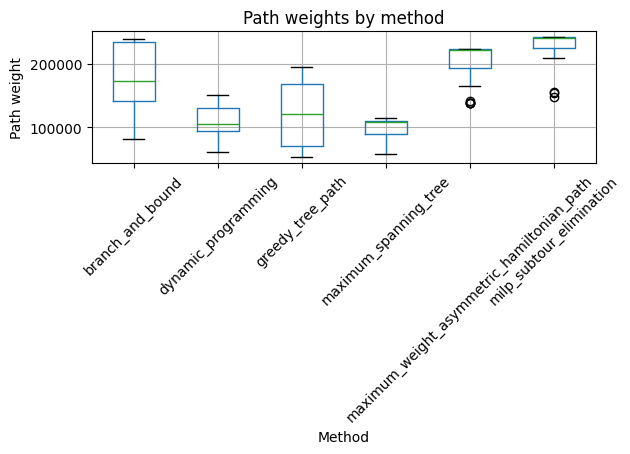

In [15]:
if plt is None:
    print("matplotlib is not installed; skipping boxplot.")
else:
    # The feedback-arc ordering optimizes a different objective and is excluded
    # here; comparing its constrained forward paths on summed_weight would
    # misrepresent it. See ordering_metrics.csv for its own scoring.
    plot_df = comparison.loc[
        comparison["method"] != "feedback_arc_ordering", ["method", "summed_weight"]
    ].copy()
    ax = plot_df.boxplot(column="summed_weight", by="method", rot=45)
    plt.suptitle("")
    plt.title("Path weights by method")
    plt.xlabel("Method")
    plt.ylabel("Path weight")
    plt.tight_layout()
    plt.show()


## Notes and references

- `mij_EE_matrix.csv` is used as the input matrix in this notebook. Every row/column label in that file is treated as an excitatory node.
- Diagonal/self entries are ignored in this notebook. The transition matrix has its diagonal set to zero before methods are run, so path scores reflect transitions between distinct excitatory nodes.
- `summed_weight` is the sum of selected positive transition weights between distinct excitatory neurons. Because all methods use the same scoring helper, score differences are attributable to path selection rather than to different objective functions.
- The greedy tree/path follows the largest positive outgoing transition to an unvisited excitatory neuron. It is fast and interpretable, but it can be trapped by locally attractive early choices.
- The maximum spanning tree method is undirected for topology; selected path scores still use the original directed transition weights. This makes it a sparse structural backbone rather than an exact directed path optimizer.
- For 32 excitatory nodes, exact full bitmask DP is usually computationally prohibitive, so the notebook defaults to beam-limited DP unless `NOTEBOOK_EXACT_DP_MAX_E_NODES` is increased.
- Beam-limited DP is not guaranteed to maximize the final path weight; it only maximizes among the states that survive the beam at each expansion step.
- Branch-and-bound is exact only when it finishes with `bb_status == "complete"`; otherwise it reports the best path found under the time/node limits. The optimistic bound was corrected to charge the edge leaving the current node; the previous bound was not admissible and could prune the optimum even on a three-node graph.
- MILP with subtour elimination is exact only when `milp_proven_optimal` is True. Do not use `pulp.LpStatus[problem.status]` for this: CBC reports `Optimal` there both when it proves optimality and when it stops on the time limit holding an incumbent. `problem.sol_status` distinguishes the two.
- The maximum-weight asymmetric Hamiltonian path is exact only when `hamiltonian_proven_optimal` is True; it is forced to visit every excitatory node exactly once, so it solves a stricter complete-ordering problem than the unconstrained MILP.
- Relevant DP computation reference: Held, M., & Karp, R. M. (1962). "A dynamic programming approach to sequencing problems." Journal of the Society for Industrial and Applied Mathematics, 10(1), 196-210. https://doi.org/10.1137/0110015.
- The feedback-arc ordering is a different objective from the path methods: it scores every positive edge against a global ordering rather than scoring one selected walk. Its per-seed paths are exact *conditional on the ordering*, because forward edges under a fixed ordering form a DAG.
- `backbone_ordering.csv` is written for reuse as `BACKBONE_LABELS` in `ei_backbone_analysis.ipynb`, which replaces the CSV-label-order placeholder that notebook currently warns about.
- Feedback-arc ordering reference: Vahidi, S. (2025). "Feedforward Ordering in Neural Connectomes via Feedback Arc Minimization." arXiv:2506.13799. https://doi.org/10.48550/arXiv.2506.13799.
- Greedy feedback-arc-set heuristic reference: Eades, P., Lin, X., & Smyth, W. F. (1993). "A fast and effective heuristic for the feedback arc set problem." Information Processing Letters, 47(6), 319-323. https://doi.org/10.1016/0020-0190(93)90079-O.
- Related connectomics use of orderings to separate feedforward from feedback structure: Borst, A. (2024). "Connectivity Matrix Seriation via Relaxation." PLOS Computational Biology, 20(2), e1011904. https://doi.org/10.1371/journal.pcbi.1011904.
- Relevant MILP subtour-elimination reference: Miller, C. E., Tucker, A. W., & Zemlin, R. A. (1960). "Integer Programming Formulation of Traveling Salesman Problems." Journal of the ACM, 7(4), 326-329. https://doi.org/10.1145/321043.321046.
